# PSFs from angular response functions (ARFs)

At high photon energies, photons cross the collimator's septa: a point source's image gains a star of penetration arms and a wide haze, which a Gaussian PSF cannot represent. [spectarf](https://github.com/stephenagraves/MCARF-to-PytomoPSF) simulates the collimator and detector once (a Monte Carlo) and keeps how they respond to a photon arriving from each direction: the angular response functions (ARFs). From them it makes the PSF at any distance from the collimator, and PyTomography's `SPECTKernelPSFTransform` applies those PSFs in a reconstruction.

This tutorial makes the ARFs of a Siemens Symbia T2 with its high energy collimator at Ac-225's 440 keV photopeak, looks at them and at the PSFs they give, and changes the camera's parameters. The Ac-225 tutorials reconstruct with them ([SIMIND](t_ac225_simind_recon.ipynb), [DICOM](t_ac225_dicom_recon.ipynb)).

It needs spectarf (`pip install "spectarf[pytomography]"`) and, for the Monte Carlo, preferably a GPU: about 1.5 minutes per camera on an RTX 5090, about half an hour on a CPU.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Ac225-NEMA-SymT2")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Ac225-NEMA-SymT2")

SPECT/Ac225-NEMA-SymT2: already downloaded


In [2]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from pytomography import io
from spectarf import Collimator, DetectorStack, DetectorResponse, EnergyResolution
from spectarf.pytomography import generate_arfs, psf_at, psf_transform, save_arfs, load_arfs

## The camera

A camera is given by name: a collimator code, a detector label and a camera, each listed with all its values on the [SPECT parameters](../spect_parameters.md) page. Each call returns plain numbers, named as spectarf's classes take them; printed, they are the values used.

In [3]:
collimator = io.SPECT.collimator('SY-HE')            # the Siemens Symbia high energy collimator
detector = io.SPECT.detector('NaI-9.5mm')            # 3/8 inch NaI(Tl), its cover and backscatter
camera = io.SPECT.camera('Siemens Symbia T')          # energy resolution model and intrinsic resolution
# Or every value explicitly:
# collimator = dict(hole_diameter_mm=4.0, septal_thickness_mm=2.0, hole_length_mm=59.7, hole_shape='hex', rotated=True, material='lead')
# detector = dict(crystal_mm=9.525, crystal_material='nai', cover_mm=1.0, cover_material='aluminium',
#                 backscatter_mm=100.0, backscatter_material='pmt')
print(collimator, detector, camera, sep='\n')

stack = DetectorStack(Collimator(**collimator), **detector)
response = DetectorResponse(EnergyResolution.geb(**camera['energy_resolution']),
                            intrinsic_fwhm_mm_140=camera['intrinsic_fwhm_mm_140'])

{'hole_diameter_mm': 4.0, 'septal_thickness_mm': 2.0, 'hole_length_mm': 59.7, 'hole_shape': 'hex', 'rotated': True, 'material': 'lead', 'code': 'SY-HE'}
{'crystal_mm': 9.525, 'crystal_material': 'nai', 'cover_mm': 1.0, 'cover_material': 'aluminium', 'backscatter_mm': 100.0, 'backscatter_material': 'pmt'}
{'name': 'Siemens Symbia T', 'energy_resolution_model': 'Morphis', 'energy_resolution': {'a_keV': -0.534, 'b': 0.946, 'c_per_keV': 0.006}, 'intrinsic_fwhm_mm_140': 3.8}


## The ARFs

`generate_arfs` takes the photopeak's photon energy (440 keV) and the energy windows from the scan's projection metadata, runs the Monte Carlo once and returns one ARF per window: the probability that a photon arriving from each direction is detected in the window, and where. Each is a table over the incidence angle θ, the azimuth φ (the hexagonal holes repeat every 60°) and the displacement (dx, dy) of the detected position from where the photon entered. spectarf caches them; `save_arfs` also keeps a copy in a folder, which `load_arfs` reads back on any machine, one without a GPU included.

In [4]:
file_NM = os.path.join(DATA, 'SPECT', 'Ac225-NEMA-SymT2', 'projection_data.IMA')
projections, object_meta, proj_meta = io.SPECT.read_dicom(file_NM)
index_peak, index_lower, index_upper = 3, 4, 5        # 396-484 keV, and the scatter windows below and above

t0 = time.time()
arfs = generate_arfs(stack, response, proj_meta, peak=index_peak, lower=index_lower, upper=index_upper)
print(f'ARFs in {time.time() - t0:.0f} s (read from the cache if this camera was simulated before)')
for name, arf in arfs.items():
    print(f"{name}: {arf.window[1]:.0f}-{arf.window[2]:.0f} keV, {arf.energy_keV:.1f} keV photons, "
          f"grid (theta, phi, dx, dy) {arf.data.shape}")
save_arfs(arfs, OUTPUT / 't_arf_psf' / 'SY-HE')
arfs = load_arfs(OUTPUT / 't_arf_psf' / 'SY-HE')       # read back: on any machine, no GPU needed

ARFs in 13 s (read from the cache if this camera was simulated before)
P: 396-484 keV, 440.0 keV photons, grid (theta, phi, dx, dy) (187, 12, 155, 155)
L: 352-396 keV, 440.0 keV photons, grid (theta, phi, dx, dy) (187, 12, 155, 155)
U: 484-572 keV, 440.0 keV photons, grid (theta, phi, dx, dy) (187, 12, 155, 155)


Below, left: the probability that a photon arriving at angle θ is detected in each window (averaged over φ). Holes 4 mm wide and 59.7 mm long accept photons within about 4°; beyond that, photons reach the crystal through the septa. Right: the photopeak window at each φ. Photons cross less lead along some directions than others, which gives the PSF its six-armed star.

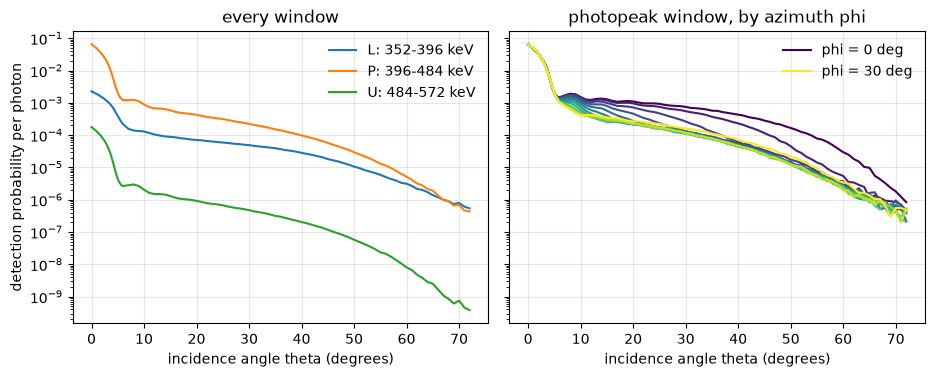

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True, gridspec_kw={'wspace': 0.05})
positive = lambda p: np.where(p > 0, p, np.nan)    # no zeros on a log axis
for name, arf in arfs.items():
    ax[0].semilogy(arf.theta_deg, positive(arf.in_window_probability().mean(axis=1)),
                   label=f"{name}: {arf.window[1]:.0f}-{arf.window[2]:.0f} keV")
P = arfs['P']
for j, phi in enumerate(P.phi_deg):
    ax[1].semilogy(P.theta_deg, positive(P.in_window_probability()[:, j]), color=plt.cm.viridis(j / max(len(P.phi_deg) - 1, 1)),
                   label=f"phi = {phi:.0f} deg" if j in (0, len(P.phi_deg) - 1) else None)
ax[0].set(xlabel='incidence angle theta (degrees)', ylabel='detection probability per photon',
          title='every window')
ax[1].set(xlabel='incidence angle theta (degrees)', title='photopeak window, by azimuth phi')
for a in ax:
    a.legend(frameon=False)
    a.grid(alpha=0.3)

## PSFs

`psf_at(arfs, distances_mm)` gives the PSF at one distance from the collimator face, or at a list of them: images of `size_mm` across with pixels of `pixel_mm`, the point source's foot at the centre, axis 0 along the projections' r and axis 1 along z. They are absolute: each pixel holds the probability that a photon emitted towards the camera is detected there, so their sum is the share of photons detected within the image (the haze reaches beyond it). Each image's log colour scale spans three decades below its peak: the penetration star's arms, and the faint haze of photons that crossed the septa in other directions.

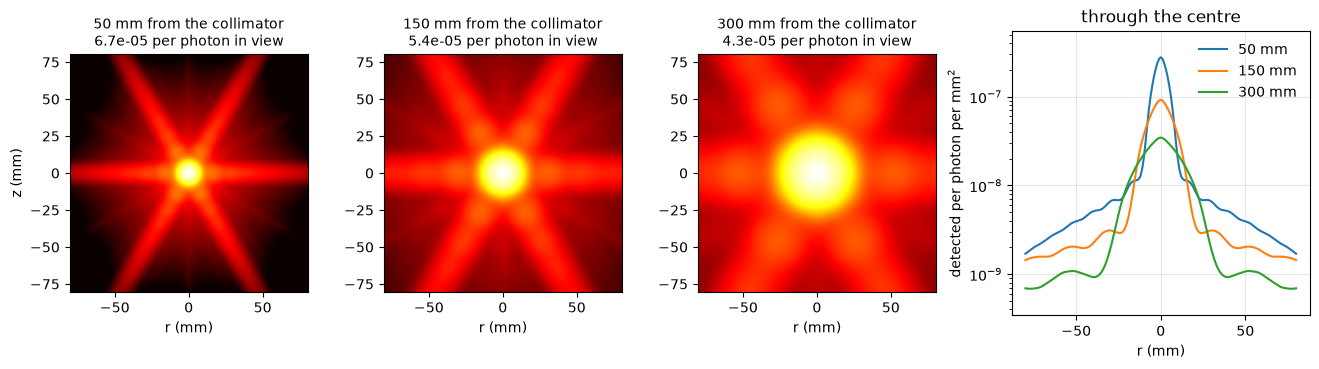

In [6]:
distances = [50.0, 150.0, 300.0]
kernels = psf_at(arfs, distances, pixel_mm=1.0, size_mm=160.0)   # (3, 161, 161), the photopeak window

w = kernels.shape[-1] * 1.0 / 2          # half width, mm
c = kernels.shape[-1] // 2
u = (np.arange(kernels.shape[-1]) - c) * 1.0
fig, ax = plt.subplots(1, 4, figsize=(16, 3.7), gridspec_kw={'width_ratios': [1, 1, 1, 1.25], 'wspace': 0.3})
for a, d, k in zip(ax, distances, kernels):
    norm = LogNorm(vmin=k.max() * 1e-3, vmax=k.max())          # three decades below each PSF's peak
    a.imshow(np.clip(k, norm.vmin, None).T, origin='lower', extent=(-w, w, -w, w), cmap='hot', norm=norm)
    a.set_title(f'{d:.0f} mm from the collimator\n{k.sum():.1e} per photon in view', fontsize=10)
    a.set_xlabel('r (mm)')
ax[0].set_ylabel('z (mm)')
for d, k in zip(distances, kernels):
    ax[3].semilogy(u, np.clip(k[:, c], 1e-14, None), label=f'{d:.0f} mm')
ax[3].set(xlabel='r (mm)', ylabel='detected per photon per mm$^2$', title='through the centre',
          ylim=(0.5 * np.clip(kernels[:, :, c], 1e-14, None).min(), 2 * kernels.max()))
ax[3].legend(frameon=False)
ax[3].grid(alpha=0.3)

## Photopeak only, or consistent with the TEW estimate

By default a kernel is the photopeak window's. The triple energy window (TEW) estimate of the scatter also takes away some of the photons that crossed the septa, since they reach the scatter windows too. `tew=True` gives the photopeak's kernel less that share, consistent with an estimate made with the same windows and weightings (`io.SPECT.energy_window_scatter`): a choice to make with the scatter correction, in `psf_at` and `psf_transform` alike.

the TEW estimate takes 10.8% of the photopeak kernel at 150 mm


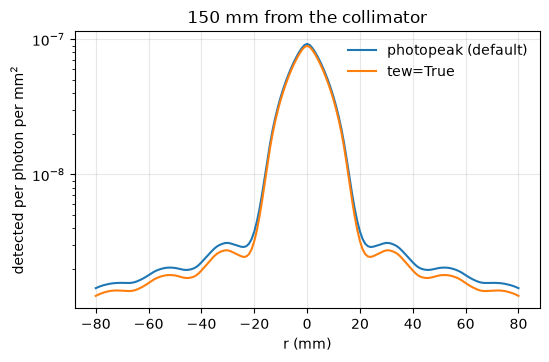

In [7]:
photopeak = psf_at(arfs, 150.0, pixel_mm=1.0, size_mm=160.0)
consistent = psf_at(arfs, 150.0, pixel_mm=1.0, size_mm=160.0, tew=True)
print(f'the TEW estimate takes {1 - consistent.sum() / photopeak.sum():.1%} of the photopeak kernel at 150 mm')
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogy(u, np.clip(photopeak[:, c], 1e-14, None), label='photopeak (default)')
ax.semilogy(u, np.clip(consistent[:, c], 1e-14, None), label='tew=True')
ax.set(xlabel='r (mm)', ylabel='detected per photon per mm$^2$', title='150 mm from the collimator')
ax.legend(frameon=False)
ax.grid(alpha=0.3)

## Changing the camera

Any value can be changed. Below, the same collimator with 1.5 mm septa instead of 2.0, given explicitly (a custom collimator: `Collimator` takes any hole diameter, septal thickness, length and material), and the 5/8 inch crystal (`NaI-15.9mm`), which stops more of the photons that penetrate. Each new camera runs the Monte Carlo once. The energy resolution is changed the same way, with another camera's model or `EnergyResolution.geb(a_keV, b, c_per_keV)` (see the Cameras tab of the parameters page).

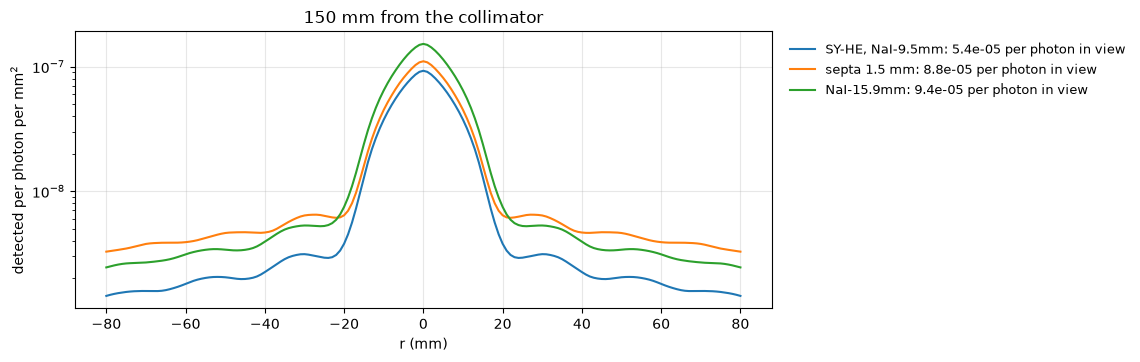

In [8]:
thin_septa = Collimator(**{**collimator, 'septal_thickness_mm': 1.5})     # a custom collimator
cameras = {
    'SY-HE, NaI-9.5mm': arfs,
    'septa 1.5 mm': generate_arfs(DetectorStack(thin_septa, **detector), response, proj_meta, peak=index_peak),
    'NaI-15.9mm': generate_arfs(DetectorStack(Collimator(**collimator), **io.SPECT.detector('NaI-15.9mm')), response,
                                proj_meta, peak=index_peak),
}
fig, ax = plt.subplots(figsize=(9, 3.6))
for label, a in cameras.items():
    k = psf_at(a, 150.0, pixel_mm=1.0, size_mm=160.0)
    ax.semilogy(u, np.clip(k[:, c], 1e-14, None), label=f'{label}: {k.sum():.1e} per photon in view')
ax.set(xlabel='r (mm)', ylabel='detected per photon per mm$^2$', title='150 mm from the collimator')
ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(1.01, 1.0))
ax.grid(alpha=0.3)

## The transform

`psf_transform(arfs)` gives PyTomography's `SPECTKernelPSFTransform`, which `SPECTSystemMatrix` takes among its object transforms (the Ac-225 tutorials reconstruct with it). Its kernels are the photopeak's and absolute by default, so a reconstruction is in emitted photons; `normalize=True` scales each kernel to sum to one, the scale of the Gaussian PSF, and `tew=True` makes them consistent with a TEW estimate.

In [9]:
psf = psf_transform(arfs)
print(type(psf).__name__, '| normalize:', psf.normalize)

SPECTKernelPSFTransform | normalize: False
